In [1]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
from langgraph.checkpoint.memory import InMemorySaver

In [2]:
load_dotenv()

llm = ChatOpenAI()

In [3]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explanation: str

In [4]:
def generate_joke(state: JokeState):

    prompt = f'generate a joke on the topic {state["topic"]}'
    response = llm.invoke(prompt).content

    return {'joke': response}

In [5]:
def generate_explanation(state: JokeState):

    prompt = f'write an explanation for the joke - {state["joke"]}'
    response = llm.invoke(prompt).content

    return {'explanation': response}

In [6]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explanation', generate_explanation)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explanation')
graph.add_edge('generate_explanation', END)

checkpointer = InMemorySaver()

workflow = graph.compile(checkpointer=checkpointer)

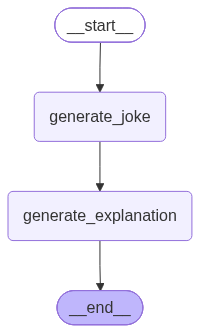

In [10]:
workflow

In [7]:
config1 = {"configurable": {"thread_id": "1"}}
workflow.invoke({'topic':'pizza'}, config=config1)

{'topic': 'pizza',
 'joke': 'Why did the pizza go to therapy? Because it felt really crust-t about itself.',
 'explanation': 'This joke plays on the pun of "crust" sounding like "crushed." The pizza went to therapy because it felt really unhappy and insecure about itself, feeling "crust-t" (crushed) in spirit. It\'s a playful way of highlighting the idea that even inanimate objects like pizza can have feelings and self-esteem issues.'}

In [8]:
workflow.get_state(config1)

StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy? Because it felt really crust-t about itself.', 'explanation': 'This joke plays on the pun of "crust" sounding like "crushed." The pizza went to therapy because it felt really unhappy and insecure about itself, feeling "crust-t" (crushed) in spirit. It\'s a playful way of highlighting the idea that even inanimate objects like pizza can have feelings and self-esteem issues.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-d11a-6690-8002-37eb0e75ba0c'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-08-13T04:44:05.270621+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-b834-66bc-8001-4584957e518d'}}, tasks=(), interrupts=())

In [9]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy? Because it felt really crust-t about itself.', 'explanation': 'This joke plays on the pun of "crust" sounding like "crushed." The pizza went to therapy because it felt really unhappy and insecure about itself, feeling "crust-t" (crushed) in spirit. It\'s a playful way of highlighting the idea that even inanimate objects like pizza can have feelings and self-esteem issues.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-d11a-6690-8002-37eb0e75ba0c'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-08-13T04:44:05.270621+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-b834-66bc-8001-4584957e518d'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': 'Why did the pizza go to therapy? Because it felt really crust-t about itself.'}, next=('generate_ex

In [11]:
config2 = {"configurable": {"thread_id": "2"}}
workflow.invoke({'topic':'pasta'}, config=config2)

{'topic': 'pasta',
 'joke': 'Why did the pasta chef go to therapy? \nBecause he was feeling too saucy!',
 'explanation': 'This joke plays on the double meaning of "saucy," which can mean either having a bold and sassy personality, or more literally, being covered in sauce. The pasta chef likely went to therapy because he was feeling too confident or bold in his actions, hence the need for some self-reflection and therapy to address his behavior. The play on words adds a humorous twist to the situation, as it is unexpected for a pasta chef to seek therapy for feeling "saucy."'}

In [12]:
workflow.get_state(config2)

StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the pasta chef go to therapy? \nBecause he was feeling too saucy!', 'explanation': 'This joke plays on the double meaning of "saucy," which can mean either having a bold and sassy personality, or more literally, being covered in sauce. The pasta chef likely went to therapy because he was feeling too confident or bold in his actions, hence the need for some self-reflection and therapy to address his behavior. The play on words adds a humorous twist to the situation, as it is unexpected for a pasta chef to seek therapy for feeling "saucy."'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f196d20-5677-630a-8002-a8e710c2e7c8'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-08-13T04:47:00.316001+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f196d20-32f9-6c3e-8001-6922b67b3d83'}}, tasks=(), interrupts=())

In [13]:
list(workflow.get_state_history(config2))

[StateSnapshot(values={'topic': 'pasta', 'joke': 'Why did the pasta chef go to therapy? \nBecause he was feeling too saucy!', 'explanation': 'This joke plays on the double meaning of "saucy," which can mean either having a bold and sassy personality, or more literally, being covered in sauce. The pasta chef likely went to therapy because he was feeling too confident or bold in his actions, hence the need for some self-reflection and therapy to address his behavior. The play on words adds a humorous twist to the situation, as it is unexpected for a pasta chef to seek therapy for feeling "saucy."'}, next=(), config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f196d20-5677-630a-8002-a8e710c2e7c8'}}, metadata={'source': 'loop', 'step': 2, 'parents': {}}, created_at='2026-08-13T04:47:00.316001+00:00', parent_config={'configurable': {'thread_id': '2', 'checkpoint_ns': '', 'checkpoint_id': '1f196d20-32f9-6c3e-8001-6922b67b3d83'}}, tasks=(), interrupts=()),
 Stat

## Time Travel

In [14]:
workflow.get_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f196d19-9c29-63a0-8000-416e914c267e"}})

StateSnapshot(values={'topic': 'pizza'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_id': '1f196d19-9c29-63a0-8000-416e914c267e'}}, metadata={'source': 'loop', 'step': 0, 'parents': {}}, created_at='2026-08-13T04:43:59.719294+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-9c19-6b76-bfff-fee595ba5c0a'}}, tasks=(PregelTask(id='c75373ee-df8e-eb73-d805-25e6f75e32f5', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result={'joke': 'Why did the pizza go to therapy? Because it felt really crust-t about itself.'}),), interrupts=())

In [15]:
workflow.invoke(None, config={"configurable": {"thread_id": "1", "checkpoint_id": "1f196d19-9c29-63a0-8000-416e914c267e"}})

{'topic': 'pizza',
 'joke': "Why did the pizza go to the therapist? Because it had too many toppings and couldn't handle the pressure!",
 'explanation': "This joke plays on the idea of pizzas having toppings and being under pressure, which is a play on words. The pizza seeking therapy because it had too many toppings and couldn't handle the pressure is a humorous way of saying that the pizza was overwhelmed by its toppings and needed help to deal with it. It's a light-hearted and silly joke that uses wordplay to create humor."}

In [16]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza go to the therapist? Because it had too many toppings and couldn't handle the pressure!", 'explanation': "This joke plays on the idea of pizzas having toppings and being under pressure, which is a play on words. The pizza seeking therapy because it had too many toppings and couldn't handle the pressure is a humorous way of saying that the pizza was overwhelmed by its toppings and needed help to deal with it. It's a light-hearted and silly joke that uses wordplay to create humor."}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d38-f924-67a2-8003-43f770f28dc1'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-08-13T04:58:01.619023+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d38-e5b6-6828-8002-17935ccfe59f'}}, tasks=(), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': "Why d

### Updating State

In [18]:
workflow.update_state({"configurable": {"thread_id": "1", "checkpoint_id": "1f196d19-9c29-63a0-8000-416e914c267e", "checkpoint_ns": ""}}, {'topic':'samosa'})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f196d3e-2874-6cdc-8001-267fe2edd254'}}

In [19]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa'}, next=('generate_joke',), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d3e-2874-6cdc-8001-267fe2edd254'}}, metadata={'source': 'update', 'step': 1, 'parents': {}}, created_at='2026-08-13T05:00:20.797932+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d19-9c29-63a0-8000-416e914c267e'}}, tasks=(PregelTask(id='a179cf6c-14c1-87b0-eb83-ee001822e2b3', name='generate_joke', path=('__pregel_pull', 'generate_joke'), error=None, interrupts=(), state=None, result=None),), interrupts=()),
 StateSnapshot(values={'topic': 'pizza', 'joke': "Why did the pizza go to the therapist? Because it had too many toppings and couldn't handle the pressure!", 'explanation': "This joke plays on the idea of pizzas having toppings and being under pressure, which is a play on words. The pizza seeking therapy because it had too many toppings and couldn't handle the pressure is a hum

In [20]:
workflow.invoke(None, {"configurable": {"thread_id": "1", "checkpoint_id": "1f196d3e-2874-6cdc-8001-267fe2edd254"}})

{'topic': 'samosa',
 'joke': 'Why did the samosa go to school? \nTo become a little more well-rounded!',
 'explanation': 'This joke plays on the double meaning of the phrase "well-rounded." In the context of education, being well-rounded means having a broad knowledge base and being skilled in multiple areas. In the case of a samosa, it is a deep-fried pastry filled with savory ingredients, typically shaped like a triangle. By going to school, the samosa humorously implies that it is trying to become physically rounder in shape while also suggesting that it is seeking to become more knowledgeable and versatile like a well-rounded student.'}

In [21]:
list(workflow.get_state_history(config1))

[StateSnapshot(values={'topic': 'samosa', 'joke': 'Why did the samosa go to school? \nTo become a little more well-rounded!', 'explanation': 'This joke plays on the double meaning of the phrase "well-rounded." In the context of education, being well-rounded means having a broad knowledge base and being skilled in multiple areas. In the case of a samosa, it is a deep-fried pastry filled with savory ingredients, typically shaped like a triangle. By going to school, the samosa humorously implies that it is trying to become physically rounder in shape while also suggesting that it is seeking to become more knowledgeable and versatile like a well-rounded student.'}, next=(), config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d42-9625-608e-8003-b00b9e88c653'}}, metadata={'source': 'loop', 'step': 3, 'parents': {}}, created_at='2026-08-13T05:02:19.673769+00:00', parent_config={'configurable': {'thread_id': '1', 'checkpoint_ns': '', 'checkpoint_id': '1f196d4